This is the second notebook on this MMM tutorial.

Here we will continue with the excersise but we start adding some complexity. Now one of the channels will have adstock and saturation effects.


In [ ]:
import numpy as np
import pandas as pd
import pytensor.tensor as pt
import pymc as pm
import matplotlib.pyplot as plt
import seaborn as sns
import arviz as az
import xarray as xr

In [ ]:

rng = np.random.default_rng(1)
n = 104

def adstock(x, alpha, L=8):
  w = alpha ** np.arange(L)
  out = np.array([sum(w[i] * x[t - i] for i in range(L) if t - i >= 0) for t in range(len(x))])
  return out / w.sum()

def saturation(x, lam):
  x=np.array(x)
  #scale x
  x=x/x.max()
  return (1 - np.exp(-lam * x)) / (1 + np.exp(-lam * x))


tv = rng.uniform(50, 100, n)* (rng.random(n) < 0.5)
social = rng.uniform(0, 50, n)

# True effects
BASE = 1000
BETA_TV = 300
ALPHA_TV = 0.6      # TV carryover: 60% of the effect remains the next week
LAMBDA= 3
BETA_SOCIAL = 5.0   # social: no carryover
NOISE = 50

sales = BASE + BETA_TV * saturation(adstock(tv, ALPHA_TV),LAMBDA) + BETA_SOCIAL * social + rng.normal(0, NOISE, n)

df = pd.DataFrame({"tv": tv.round(1), "social": social.round(1), "sales": sales.round(0)})

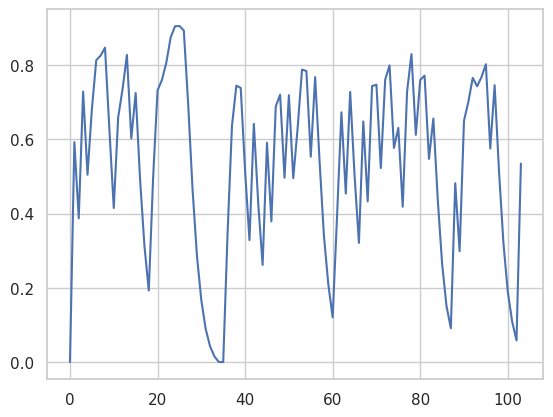

In [ ]:
a= saturation(adstock(tv, ALPHA_TV),LAMBDA)
plt.plot(a)

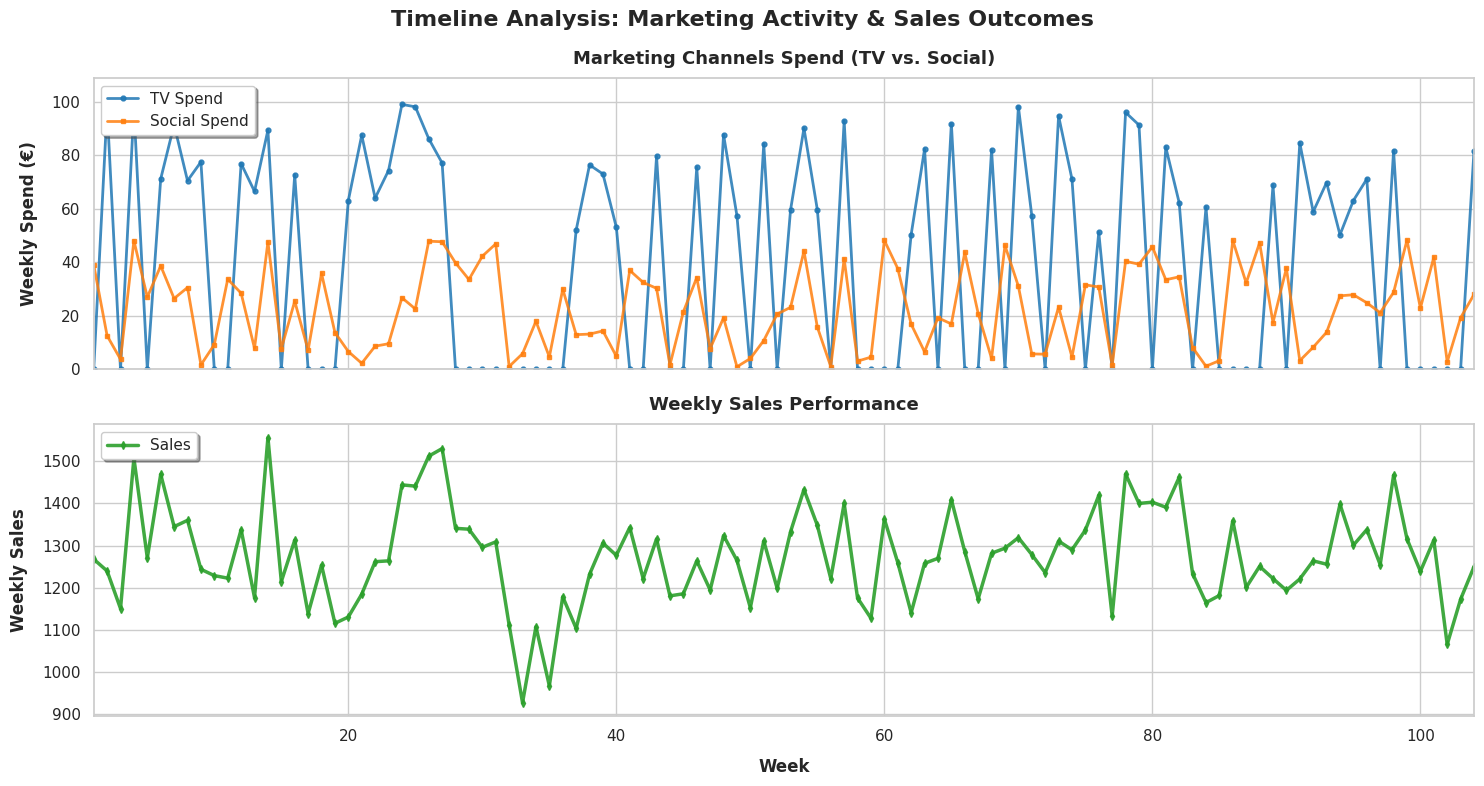

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure styling
sns.set_theme(style="whitegrid")
timeline = range(1, len(df) + 1)

# Create a 2-row stacked subplot sharing the X-axis (Timeline)
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(15, 8), sharex=True)

# Panel 1: Marketing Spends
color_tv = '#1f77b4'
color_social = '#ff7f0e'

ax1.plot(timeline, df['tv'], label='TV Spend', color=color_tv, linewidth=2, marker='o', markersize=3.5, alpha=0.85)
ax1.plot(timeline, df['social'], label='Social Spend', color=color_social, linewidth=2, marker='s', markersize=3.5, alpha=0.85)

ax1.set_ylabel('Weekly Spend (€)', fontsize=12, fontweight='bold', labelpad=10)
ax1.set_title('Marketing Channels Spend (TV vs. Social)', fontsize=13, fontweight='bold', pad=10)
ax1.legend(loc='upper left', frameon=True, facecolor='white', shadow=True)
ax1.set_ylim(0, max(df['tv'].max(), df['social'].max()) * 1.1)

# Panel 2: Resulting Sales
color_sales = '#2ca02c'

ax2.plot(timeline, df['sales'], label='Sales', color=color_sales, linewidth=2.5, marker='d', markersize=4, alpha=0.9)
ax2.set_xlabel('Week', fontsize=12, fontweight='bold', labelpad=10)
ax2.set_ylabel('Weekly Sales', fontsize=12, fontweight='bold', labelpad=10)
ax2.set_title('Weekly Sales Performance', fontsize=13, fontweight='bold', pad=10)
ax2.legend(loc='upper left', frameon=True, facecolor='white', shadow=True)
ax2.set_xlim(1, len(df))

# Adjust spacing and display
plt.suptitle('Timeline Analysis: Marketing Activity & Sales Outcomes', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

## Naive regression

We will run now the OLS regression. It is interesting to see that running this regression already shows us that the model is not  delivering the expected results even at p < 0.001 and though the channels are independent. what is going on?


We added adstock effects!

In [ ]:
import statsmodels.formula.api as smf

ols_model = smf.ols(formula="sales ~ tv + social", data=df).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.681
Model:                            OLS   Adj. R-squared:                  0.675
Method:                 Least Squares   F-statistic:                     107.8
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           8.83e-26
Time:                        15:22:31   Log-Likelihood:                -579.61
No. Observations:                 104   AIC:                             1165.
Df Residuals:                     101   BIC:                             1173.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1109.4734     12.933     85.788      0.0

TV = 1.20, with a 95% interval of 0.56–1.85. The true value, 3, is far outside it. --> with adstock effects only

TV= 0.13 (p_vale=0.66) with saturation effects included.


In [ ]:
#PyMC model

import pymc as pm
import pytensor.tensor as pt

channels = ['tv', 'social']

X = df[channels].values
y = df['sales'].values



X = X / X.max(axis=0)          # each channel between 0 and 1
y_scale = y.max()
y = y / y_scale                # sales between 0 and 1

def adstock_effect(x,alpha,L=8):
  w = alpha ** pt.arange(L)
  lagged = pt.stack([pt.concatenate([pt.zeros(i), x[:x.shape[0] - i]]) for i in range(L)])
  return pt.dot(w, lagged) / w.sum()

def saturation(x, lam):
  x=np.array(x)
  return (1 - np.exp(-lam * x)) / (1 + np.exp(-lam * x))



with pm.Model() as model:

    intercept = pm.Normal("intercept", 0.5, 0.25)

    media = 0

  #priors
    sigma = pm.HalfNormal("sigma", 0.1)
    lam_tv= pm.Normal("lam_tv", 7,1)
    beta_tv = pm.HalfNormal(f"beta_tv", 0.7)
    alpha_tv= pm.Beta(f"alpha_tv", 2,2)

    beta_social = pm.HalfNormal(f"beta_social", 0.7)

    #likelyhood
    ad = adstock_effect(X[:, 0], alpha_tv)
    sat=saturation(ad,lam_tv)

    media = beta_tv*sat + beta_social*X[:,1]


    #model
    mu = intercept + media
    pm.Normal("y", mu=mu, sigma=sigma, observed=y)


    prior = pm.sample_prior_predictive()
    idata = pm.sample()



Output()

<Axes: xlabel='y'>

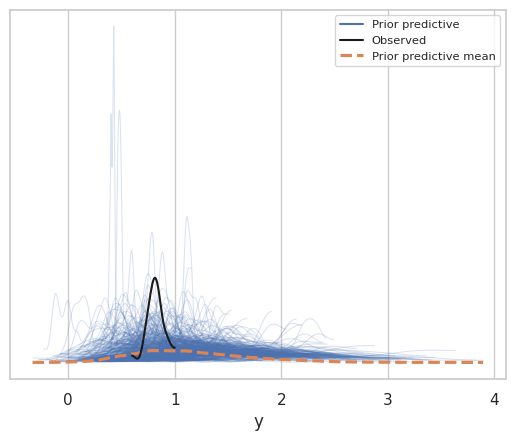

In [ ]:
import arviz as az
az.plot_ppc(prior, group="prior", observed=True)

In [ ]:
post = idata.posterior
x_max = df[channels].max().values


print("intercept:", (post["intercept"] * y_scale).mean().item())
print("sigma:", (post["sigma"] * y_scale).mean().item())
for i, ch in enumerate(channels):
    print(ch, (post[f"beta_{ch}"] * y_scale / x_max[i]).mean().item())

intercept: 993.3317854798887
sigma: 47.98067922753114
tv 2.968885666761739
social 4.885364462307673


In [ ]:
# True effects
# BASE = 1000
# BETA_TV = 3.0
# ALPHA_TV = 0.6      # TV carryover: 60% of the effect remains the next week
# BETA_SOCIAL = 5.0   # social: no carryover
# NOISE = 50

In [ ]:
import arviz as az
import xarray as xr

real = xr.Dataset({
    "intercept": post["intercept"] * y_scale,
    "sigma": post["sigma"] * y_scale,
    "beta_tv": post["beta_tv"] * y_scale,  # Saturation output is 0-1, so we do not divide by x_max
    "beta_social": post["beta_social"] * y_scale / x_max[1]  # Linear channel, divide by x_max
})

print(az.summary(real))

                mean      sd   hdi_3%   hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
intercept    993.332  17.304  960.355  1025.223      0.508    0.401    1168.0   
sigma         47.981   3.450   41.564    54.071      0.096    0.083    1319.0   
beta_tv      293.920  30.387  238.818   350.202      0.934    0.786    1069.0   
beta_social    4.885   0.323    4.247     5.453      0.009    0.007    1221.0   

             ess_tail  r_hat  
intercept      1254.0    1.0  
sigma          1275.0    1.0  
beta_tv        1016.0    1.0  
beta_social    1204.0    1.0  


In [ ]:
print("--- Correctly Unscaled Parameters ---")
print(f"Intercept (True: {BASE}):", (post["intercept"] * y_scale).mean().item())
print(f"beta_social (True: {BETA_SOCIAL}):", (post["beta_social"] * y_scale / x_max[1]).mean().item())
# Since saturation output is 0 to 1, beta_tv is only scaled by y_scale, not x_max
print(f"beta_tv (True: {BETA_TV}):", (post["beta_tv"] * y_scale).mean().item())
print(f"alpha_tv (True: {ALPHA_TV}):", post["alpha_tv"].mean().item())
print(f"lambda_tv (True: {LAMBDA}):", post["lam_tv"].mean().item())
print(f"sigma (True: {NOISE}):", (post["sigma"] * y_scale).mean().item())

--- Correctly Unscaled Parameters ---
Intercept (True: 1000): 993.3317854798887
beta_social (True: 5.0): 4.885364462307673
beta_tv (True: 300): 293.91968100941267
alpha_tv (True: 0.6): 0.6149391334485891
lambda_tv (True: 3): 3.9138569169809276
sigma (True: 50): 47.98067922753114


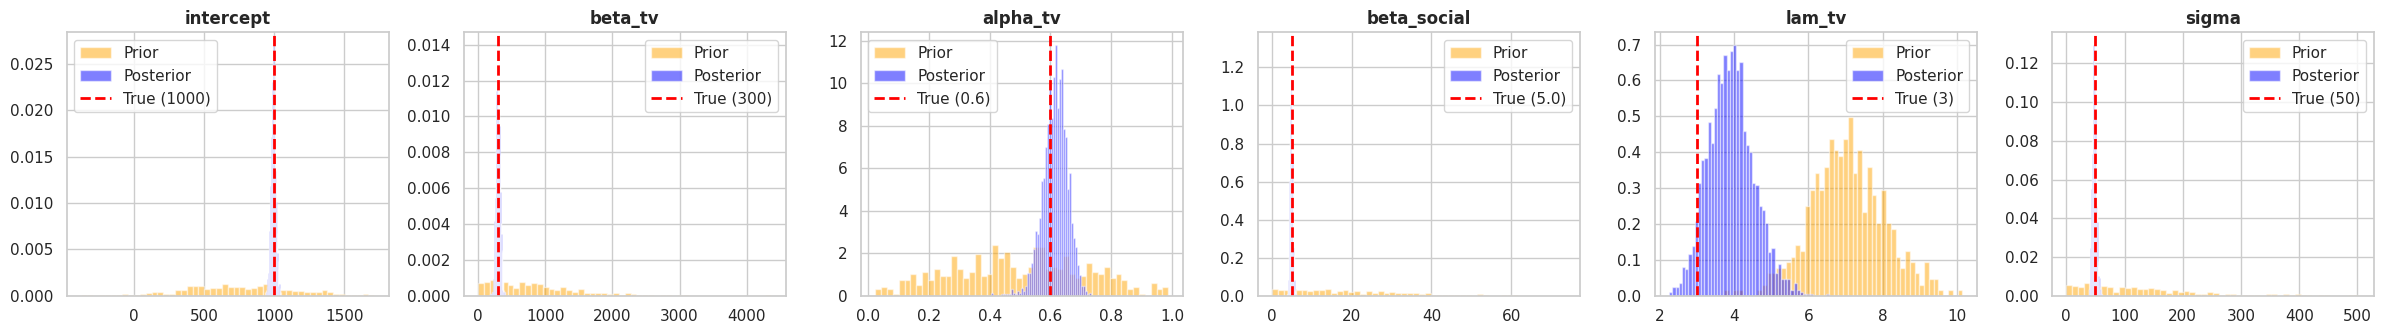

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Map both scaled prior and posterior samples to their unscaled real-world scales
unscaled_prior = {
    "intercept": prior.prior["intercept"].values.flatten() * y_scale,
    "beta_tv": prior.prior["beta_tv"].values.flatten() * y_scale,
    "alpha_tv": prior.prior["alpha_tv"].values.flatten(),
    "beta_social": prior.prior["beta_social"].values.flatten() * y_scale / x_max[1],
    "lam_tv": prior.prior["lam_tv"].values.flatten(),
    "sigma": prior.prior["sigma"].values.flatten() * y_scale
}

unscaled_posterior = {
    "intercept": idata.posterior["intercept"].values.flatten() * y_scale,
    "beta_tv": idata.posterior["beta_tv"].values.flatten() * y_scale,
    "alpha_tv": idata.posterior["alpha_tv"].values.flatten(),
    "beta_social": idata.posterior["beta_social"].values.flatten() * y_scale / x_max[1],
    "lam_tv": idata.posterior["lam_tv"].values.flatten(),
    "sigma": idata.posterior["sigma"].values.flatten() * y_scale
}

true_values = {
    "intercept": BASE,
    "beta_tv": BETA_TV,
    "alpha_tv": ALPHA_TV,
    "beta_social": BETA_SOCIAL,
    "lam_tv": LAMBDA,
    "sigma": NOISE
}

vars_to_plot = ["intercept", "beta_tv", "alpha_tv", "beta_social", "lam_tv", "sigma"]

fig, axes = plt.subplots(1, len(vars_to_plot), figsize=(4 * len(vars_to_plot), 3.5))
for ax, v in zip(axes, vars_to_plot):
    # Plot Prior vs Posterior
    ax.hist(unscaled_prior[v], bins=50, density=True, alpha=0.5, color='orange', label="Prior")
    ax.hist(unscaled_posterior[v], bins=50, density=True, alpha=0.5, color='blue', label="Posterior")

    # Add a red dashed line representing the true ground-truth value
    ax.axvline(true_values[v], color='red', linestyle='--', linewidth=2, label=f"True ({true_values[v]})")

    ax.set_title(v, fontsize=12, fontweight='bold')
    ax.legend()

plt.tight_layout()
plt.show()

Interesting results: When staruation effects are modelled with lamda =6 on an unscaled spend!, it means that then channel is highly saturated along the whole period. Therefore, for every week you get some sales, no matter what. This is why the posterior of beta_TV goes from zero to 0.3. In other words it cannot rule out no effect.

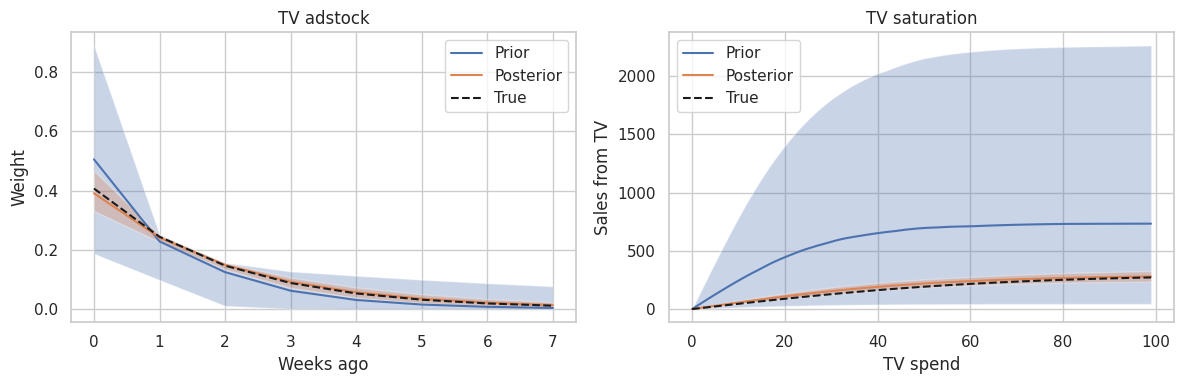

In [ ]:
import matplotlib.pyplot as plt

def draws(group, name):
    return group[name].values.flatten()

def band(curves):
    return np.percentile(curves, [3, 50, 97], axis=0)   # lower, median, upper

# ---------- Adstock: weight of each past week ----------
L = 8
k = np.arange(L)

def decay_curves(alpha):
    w = alpha[:, None] ** k                  # one row per draw
    return w / w.sum(axis=1, keepdims=True)  # normalized, like in the model

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for group, label in [(prior.prior, "Prior"), (idata.posterior, "Posterior")]:
    lo, med, hi = band(decay_curves(draws(group, "alpha_tv")))
    ax[0].plot(k, med, label=label)
    ax[0].fill_between(k, lo, hi, alpha=0.3)
ax[0].plot(k, decay_curves(np.array([0.6]))[0], "k--", label="True")
ax[0].set(title="TV adstock", xlabel="Weeks ago", ylabel="Weight")
ax[0].legend()

# ---------- Saturation: sales from TV vs spend ----------
x = np.linspace(0, 1, 100)   # scaled spend

def sat_curves(group):
    lam = draws(group, "lam_tv")[:, None]
    beta = draws(group, "beta_tv")[:, None]
    return beta * (1 - np.exp(-lam * x)) / (1 + np.exp(-lam * x)) * y_scale   # in sales

spend = x * df["tv"].max()   # back to real spend
for group, label in [(prior.prior, "Prior"), (idata.posterior, "Posterior")]:
    lo, med, hi = band(sat_curves(group))
    ax[1].plot(spend, med, label=label)
    ax[1].fill_between(spend, lo, hi, alpha=0.3)
ax[1].plot(spend, 300 * (1 - np.exp(-3 * x)) / (1 + np.exp(-3 * x)), "k--", label="True")
ax[1].set(title="TV saturation", xlabel="TV spend", ylabel="Sales from TV")
ax[1].legend()

plt.tight_layout()
plt.show()